# Auto MPG Dataset — Exploratory Data Analysis & Preprocessing

**Objective:** Explore the Auto MPG dataset, clean it up, and understand what drives a car's fuel efficiency (miles per gallon).

**Dataset:** Auto MPG — 398 cars from the 1970s–80s, with specs like cylinders, horsepower, weight, displacement, acceleration, model year and origin.

**What is EDA & preprocessing?** Exploratory Data Analysis (EDA) means looking at a dataset from different angles — checking its shape, spotting missing or weird values, and visualizing relationships between columns — *before* doing anything else with it. Preprocessing is the clean-up step: fixing data types, handling missing values, and removing duplicates so the dataset is reliable to work with.

*Submitted for: Coding Ninjas 10X AI-ML Club — Task 1*

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Dataset Loading

Each row in this dataset represents **one car model**, described by its fuel efficiency (mpg) and technical specifications.

In [2]:
df = pd.read_csv("auto-mpg.csv")

print("First 5 rows:")
df.head()

First 5 rows:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [3]:
print("Last 5 rows:")
df.tail()

Last 5 rows:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
393,27.0,4,140.0,86.00,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.00,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.00,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.00,2625.0,18.6,82,1,ford ranger
397,31.0,4,119.0,82.00,2720.0,19.4,82,1,chevy s-10


In [4]:
print("Shape of the dataset (rows, columns):", df.shape)

Shape of the dataset (rows, columns): (398, 9)


## 3. Dataset Inspection

In [5]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))

Shape: (398, 9)

Columns: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [7]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [8]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical / text columns:", categorical_cols)

Numerical columns: ['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model_year', 'origin']
Categorical / text columns: ['horsepower', 'car_name']


**Column type summary:**

| Column | Type | Description |
|---|---|---|
| mpg | Numerical | Miles per gallon (target/outcome variable) |
| cylinders | Numerical (discrete) | Number of engine cylinders |
| displacement | Numerical | Engine displacement (cubic inches) |
| horsepower | Numerical (stored as text) | Engine horsepower — needs cleaning |
| weight | Numerical | Vehicle weight (lbs) |
| acceleration | Numerical | Time to accelerate (seconds) |
| model_year | Numerical (discrete) | Year of the model (70 = 1970, etc.) |
| origin | Categorical (coded) | 1 = USA, 2 = Europe, 3 = Japan |
| car_name | Categorical (text) | Car make and model |

Even though `horsepower` looks numeric, pandas read it as text — this is investigated in Section 5.

## 4. Missing Values Analysis

Before checking for missing values, `horsepower`'s hidden `"?"` placeholders need to become real `NaN`s first — otherwise pandas won't count them as missing at all.

In [9]:
df["horsepower"] = df["horsepower"].replace("?", np.nan)
df["horsepower"] = pd.to_numeric(df["horsepower"])

print("horsepower converted to numeric. Missing values in horsepower:", df["horsepower"].isnull().sum())

horsepower converted to numeric. Missing values in horsepower: 6


In [10]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({"Missing Count": missing_count, "Missing %": missing_percent.round(2)})
missing_df

,Missing Count,Missing %
mpg,0,0.00
cylinders,0,0.00
displacement,0,0.00
horsepower,6,1.51
weight,0,0.00
acceleration,0,0.00
model_year,0,0.00
origin,0,0.00
car_name,0,0.00


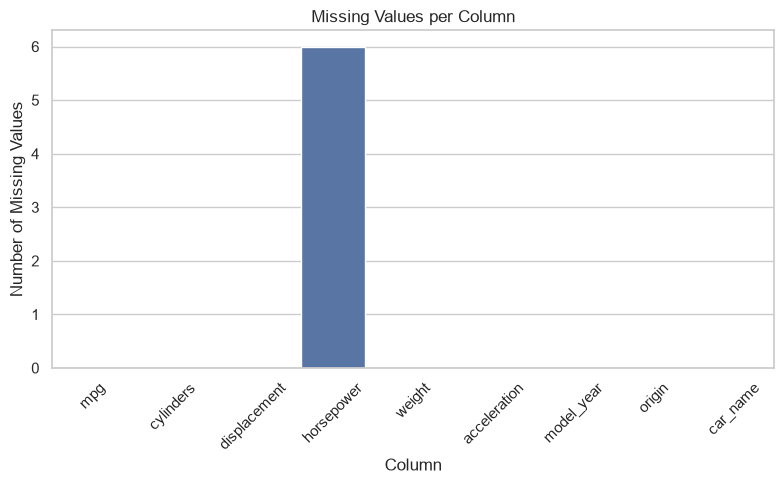

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(x=missing_df.index, y=missing_df["Missing Count"])
plt.title("Missing Values per Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation:** `horsepower`'s `"?"` placeholders were converted to NaN just above, so `isnull()` now correctly shows 6 missing values, all in `horsepower`. Every other column is complete.

## 5. Duplicate Records Analysis

In [12]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [13]:
duplicate_rows = df[df.duplicated()]
duplicate_rows

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name


In [14]:
rows_before = df.shape[0]
df = df.drop_duplicates()
rows_after = df.shape[0]

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Duplicate rows removed:", rows_before - rows_after)

Rows before removing duplicates: 398
Rows after removing duplicates: 398
Duplicate rows removed: 0


**Observation:** No duplicate rows were found here, so nothing was removed. It's still worth checking every time though — a duplicate row would count the same car twice, which quietly pulls averages like mean mpg and the correlation numbers in the wrong direction without it being obvious.

## 6. Data Type Correction

`horsepower` was stored as text because of the hidden `"?"` placeholders. It was already converted to numeric back in the Missing Values Analysis step (so that step could report the real missing count) — here's a quick confirmation that it stuck.

In [15]:
print("Current dtype of horsepower:", df["horsepower"].dtype)
print("Rows with '?' in horsepower:", (df["horsepower"] == "?").sum())
df[df["horsepower"] == "?"]

Current dtype of horsepower: float64
Rows with '?' in horsepower: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name


**Why this conversion was needed:** `horsepower` should behave like a number so we can use it in statistics, correlations, and plots. Converting `"?"` to `NaN` and casting the column to numeric fixes this while correctly marking the 6 unknown values as missing instead of hiding them as text.

## 7. Missing Value Handling

In [16]:
print("Missing values BEFORE cleaning:")
print(df.isnull().sum())

Missing values BEFORE cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


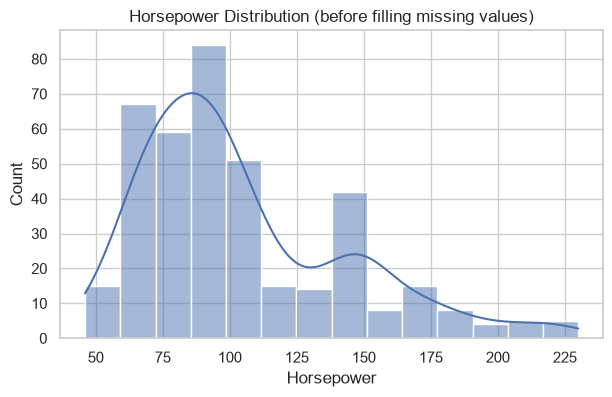

In [17]:
plt.figure(figsize=(7, 4))
sns.histplot(df["horsepower"].dropna(), kde=True)
plt.title("Horsepower Distribution (before filling missing values)")
plt.xlabel("Horsepower")
plt.ylabel("Count")
plt.show()

The horsepower distribution is **right-skewed** (a few cars have very high horsepower, pulling the mean up). For skewed numeric columns, the **median** is a better fill value than the mean, since it isn't dragged around by extreme values.

In [18]:
horsepower_median = df["horsepower"].median()
df["horsepower"] = df["horsepower"].fillna(horsepower_median)

print("Filled missing horsepower values with median:", horsepower_median)
print("\nMissing values AFTER cleaning:")
print(df.isnull().sum())

Filled missing horsepower values with median: 93.5

Missing values AFTER cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


**Note:** No rows were dropped. With only 6 out of 398 rows affected (~1.5%), filling with the median preserves all the data instead of throwing away otherwise-complete records.

## 8. Suspicious Records Investigation

Checking for values that would be physically impossible for a real car.

In [19]:
suspicious = df[
    (df["horsepower"] <= 0) |
    (df["weight"] <= 0) |
    (df["acceleration"] <= 0) |
    (df["mpg"] <= 0) |
    (~df["cylinders"].isin([3, 4, 5, 6, 8]))
]
print("Number of impossible-value rows found:", suspicious.shape[0])

# Not impossible, but extreme - worth a closer look
print("Highest horsepower cars:")
print(df.nlargest(3, "horsepower")[["car_name", "horsepower", "cylinders", "mpg"]])

print("\nLowest mpg cars:")
print(df.nsmallest(3, "mpg")[["car_name", "mpg", "cylinders", "horsepower", "weight"]])

print("\nHighest mpg cars:")
print(df.nlargest(3, "mpg")[["car_name", "mpg", "cylinders", "horsepower", "weight"]])

Number of impossible-value rows found: 0
Highest horsepower cars:
                    car_name  horsepower  cylinders   mpg
116       pontiac grand prix       230.0          8  16.0
8           pontiac catalina       225.0          8  14.0
13   buick estate wagon (sw)       225.0          8  14.0

Lowest mpg cars:
     car_name   mpg  cylinders  horsepower  weight
28   hi 1200d   9.0          8       193.0  4732.0
25  ford f250  10.0          8       215.0  4615.0
26  chevy c20  10.0          8       200.0  4376.0

Highest mpg cars:
                 car_name   mpg  cylinders  horsepower  weight
322             mazda glc  46.6          4        65.0  2110.0
329   honda civic 1500 gl  44.6          4        67.0  1850.0
325  vw rabbit c (diesel)  44.3          4        48.0  2085.0


**Observation:** Two things were checked here — physically impossible values (none found: no zero/negative horsepower, weight, acceleration or mpg, and every cylinder count is real) and unusually extreme-but-possible values (highest horsepower, lowest mpg, highest mpg). The extreme cases all check out as genuine cars — heavy 8-cylinders at the low-mpg end, light 4-cylinders at the high-mpg end — so nothing was removed; they're kept as real vehicles, not errors.

## 9. Final Clean Dataset Summary

In [20]:
summary = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing values", "Duplicate rows"],
    "Before Cleaning": [398, 9, 0, 0],
    "After Cleaning": [df.shape[0], df.shape[1], df.isnull().sum().sum(), df.duplicated().sum()]
})
summary

,Metric,Before Cleaning,After Cleaning
0,Rows,398,398
1,Columns,9,9
2,Missing values,0,0
3,Duplicate rows,0,0


In [21]:
print("Final shape:", df.shape)
print("Rows removed overall:", 398 - df.shape[0])
print("Columns unchanged:", df.shape[1] == 9)
print("Missing values remaining:", df.isnull().sum().sum())

Final shape: (398, 9)
Rows removed overall: 0
Columns unchanged: True
Missing values remaining: 0


**Observation:** The only real fix needed was converting `horsepower` to numeric and filling 6 missing values with the median. No rows or columns were dropped, so the dataset is still complete at 398 cars.

# Exploratory Data Analysis

## A. MPG Distribution

**Question:** What does the spread of fuel efficiency (mpg) look like across all cars?

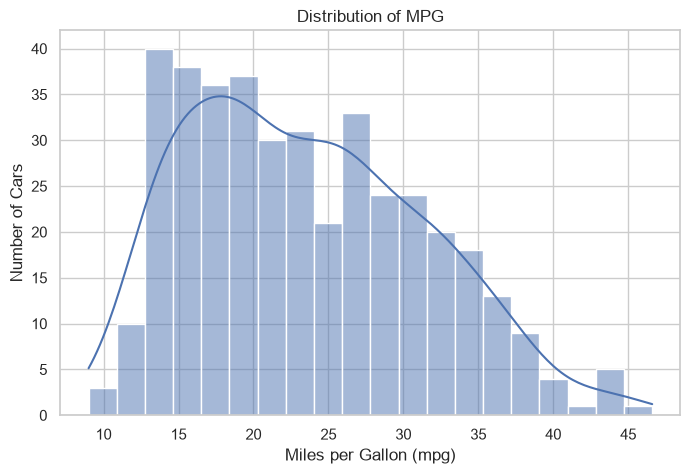

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(df["mpg"], kde=True, bins=20)
plt.title("Distribution of MPG")
plt.xlabel("Miles per Gallon (mpg)")
plt.ylabel("Number of Cars")
plt.show()

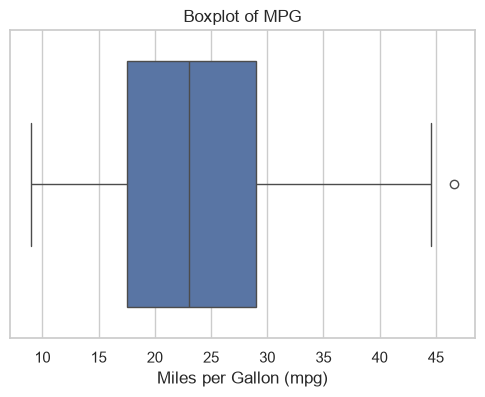

In [23]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["mpg"])
plt.title("Boxplot of MPG")
plt.xlabel("Miles per Gallon (mpg)")
plt.show()

In [24]:
print("Mean mpg:", round(df["mpg"].mean(), 2))
print("Median mpg:", round(df["mpg"].median(), 2))
print("Std deviation:", round(df["mpg"].std(), 2))
print("Min mpg:", df["mpg"].min())
print("Max mpg:", df["mpg"].max())

Mean mpg: 23.51
Median mpg: 23.0
Std deviation: 7.82
Min mpg: 9.0
Max mpg: 46.6


**Observation:** MPG ranges from about 9 to 46.6, with a mean around 23.5 and median around 23. The histogram is slightly right-skewed — most cars cluster between 15–30 mpg, with a smaller tail of very fuel-efficient cars above 35 mpg. The boxplot shows no extreme low-end outliers, but a few high-mpg cars stretch the upper whisker.

## B. Relationship Between MPG and Three Variables

**Question:** How do weight, horsepower and displacement individually relate to mpg?

These three were picked because they all showed up as the columns most correlated with mpg during inspection, and they're the specs people usually mean when they call a car "big" or "powerful."

### B.1 MPG vs Weight

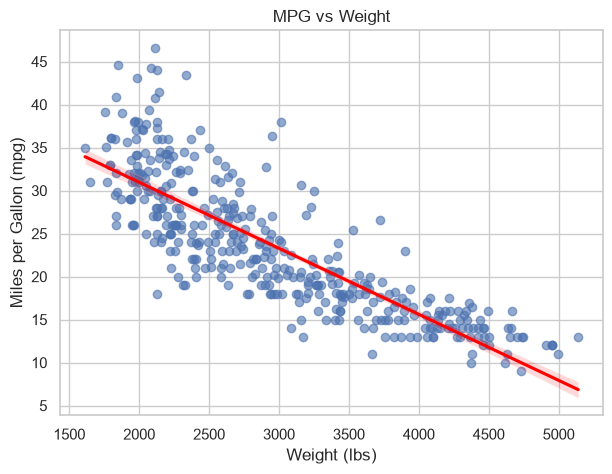

In [25]:
plt.figure(figsize=(7, 5))
sns.regplot(x="weight", y="mpg", data=df, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
plt.title("MPG vs Weight")
plt.xlabel("Weight (lbs)")
plt.ylabel("Miles per Gallon (mpg)")
plt.show()

**Observation:** There is a clear **negative relationship** — heavier cars consistently get lower mpg. The points follow the downward trendline closely, suggesting weight is one of the strongest predictors of fuel efficiency in this dataset.

### B.2 MPG vs Horsepower

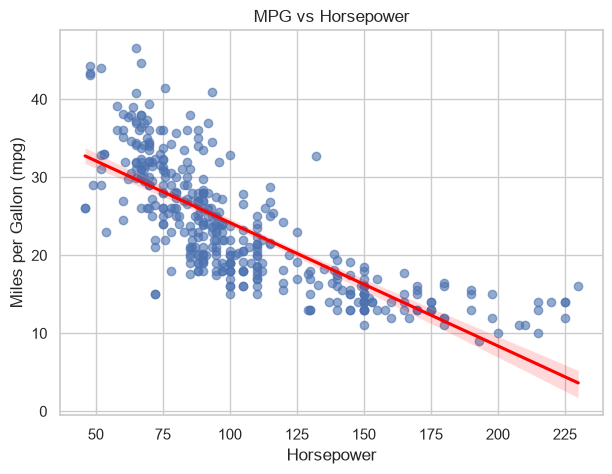

In [26]:
plt.figure(figsize=(7, 5))
sns.regplot(x="horsepower", y="mpg", data=df, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
plt.title("MPG vs Horsepower")
plt.xlabel("Horsepower")
plt.ylabel("Miles per Gallon (mpg)")
plt.show()

**Observation:** MPG also drops as horsepower increases, but the relationship looks slightly **curved rather than perfectly straight** — mpg falls sharply up to around 150 hp, then flattens out for very high-horsepower cars.

### B.3 MPG vs Displacement

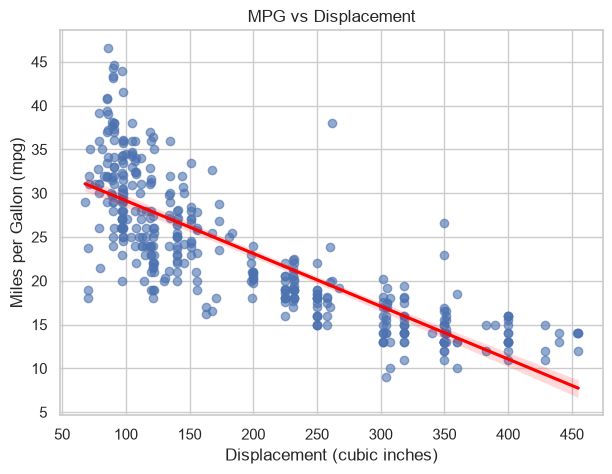

In [27]:
plt.figure(figsize=(7, 5))
sns.regplot(x="displacement", y="mpg", data=df, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
plt.title("MPG vs Displacement")
plt.xlabel("Displacement (cubic inches)")
plt.ylabel("Miles per Gallon (mpg)")
plt.show()

**Observation:** Displacement shows the same negative pattern as weight and horsepower — bigger engines mean lower mpg. This makes sense since displacement, horsepower and weight tend to move together in larger cars.

## C. Compare MPG Across Two Meaningful Groups

**Question:** Does mpg differ by number of cylinders or by where the car was made?

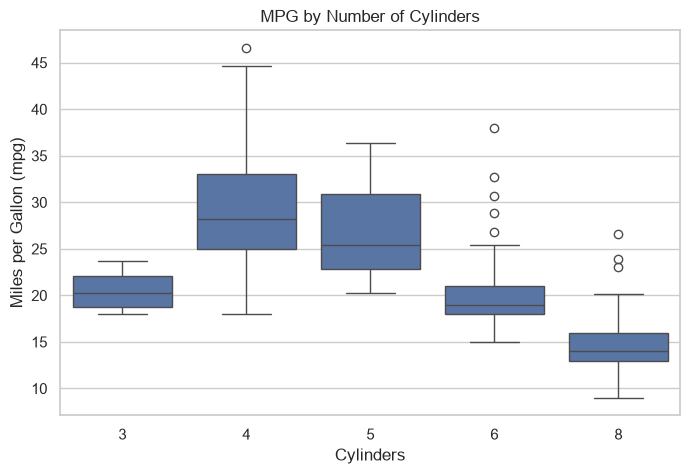

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="cylinders", y="mpg", data=df)
plt.title("MPG by Number of Cylinders")
plt.xlabel("Cylinders")
plt.ylabel("Miles per Gallon (mpg)")
plt.show()

**Observation:** MPG drops steadily as cylinder count rises. 4-cylinder cars have the highest and most spread-out mpg values, while 8-cylinder cars are tightly clustered at the low end (mostly under 20 mpg).

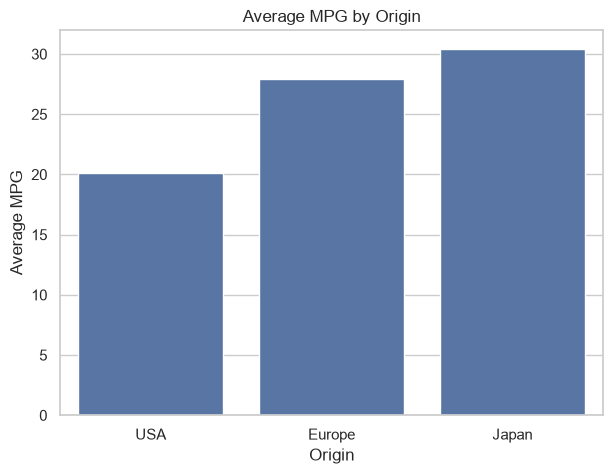

In [29]:
origin_map = {1: "USA", 2: "Europe", 3: "Japan"}
df["origin_name"] = df["origin"].map(origin_map)

avg_mpg_by_origin = df.groupby("origin_name")["mpg"].mean().sort_values()

plt.figure(figsize=(7, 5))
sns.barplot(x=avg_mpg_by_origin.index, y=avg_mpg_by_origin.values)
plt.title("Average MPG by Origin")
plt.xlabel("Origin")
plt.ylabel("Average MPG")
plt.show()

**Observation:** Japanese cars have the highest average mpg, followed by European cars, with American cars lowest. This lines up with Section B — American cars in this dataset tend to be heavier, higher-displacement vehicles.

## D. Correlation Analysis

**Question:** How strongly are the numeric columns related to each other?

In [30]:
corr_cols = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
correlation_matrix = df[corr_cols].corr()
correlation_matrix

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
mpg,1.000000,-0.775396,-0.804203,-0.773453,-0.831741,0.420289,0.579267
cylinders,-0.775396,1.000000,0.950721,0.841284,0.896017,-0.505419,-0.348746
displacement,-0.804203,0.950721,1.000000,0.895778,0.932824,-0.543684,-0.370164
horsepower,-0.773453,0.841284,0.895778,1.000000,0.862442,-0.686590,-0.413733
weight,-0.831741,0.896017,0.932824,0.862442,1.000000,-0.417457,-0.306564
acceleration,0.420289,-0.505419,-0.543684,-0.686590,-0.417457,1.000000,0.288137
model_year,0.579267,-0.348746,-0.370164,-0.413733,-0.306564,0.288137,1.000000


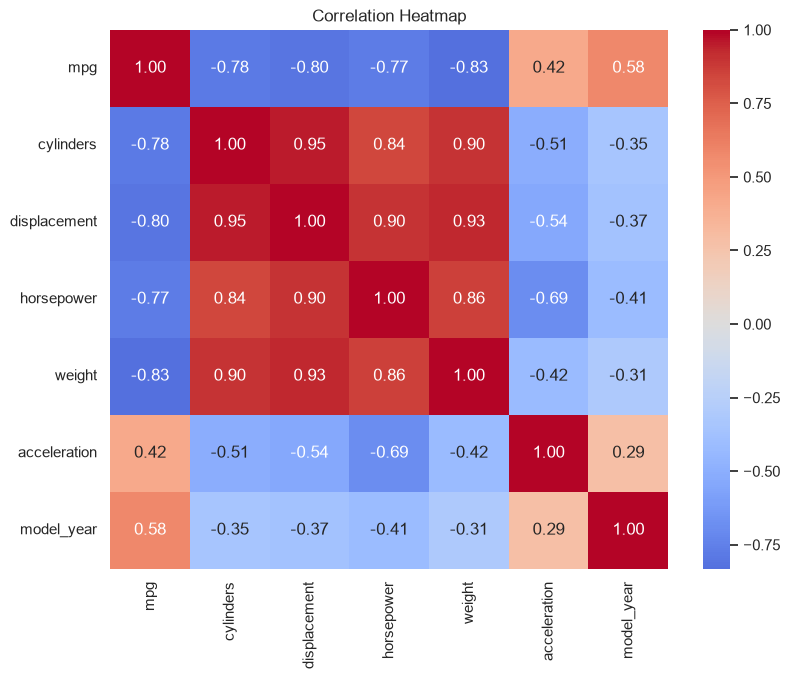

In [31]:
plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

**Observation:**
- **Strongest negative correlations:** `weight` (-0.83) and `displacement` (-0.80) with mpg — bigger, heavier cars are the least fuel-efficient.
- **Strongest positive correlation:** `model_year` (+0.58) with mpg — newer cars in the dataset tend to be more fuel-efficient, likely reflecting design changes after the 1970s fuel crisis.
- **Weak correlation:** `acceleration` (~+0.42) has a moderate but much weaker link to mpg than weight or displacement.

These are correlations, **not proof of cause and effect** — a heavier car doesn't get lower mpg *because* it's heavy in some isolated sense; weight, engine size and horsepower all move together as a bundle of "how big is this car" traits.

Weight has the single strongest negative correlation with mpg out of all the numeric columns, but that's still just a correlation — it doesn't prove weight by itself *causes* lower mpg.

## E. Outlier Investigation

**Question:** Are there any individual cars that stand apart from the rest?

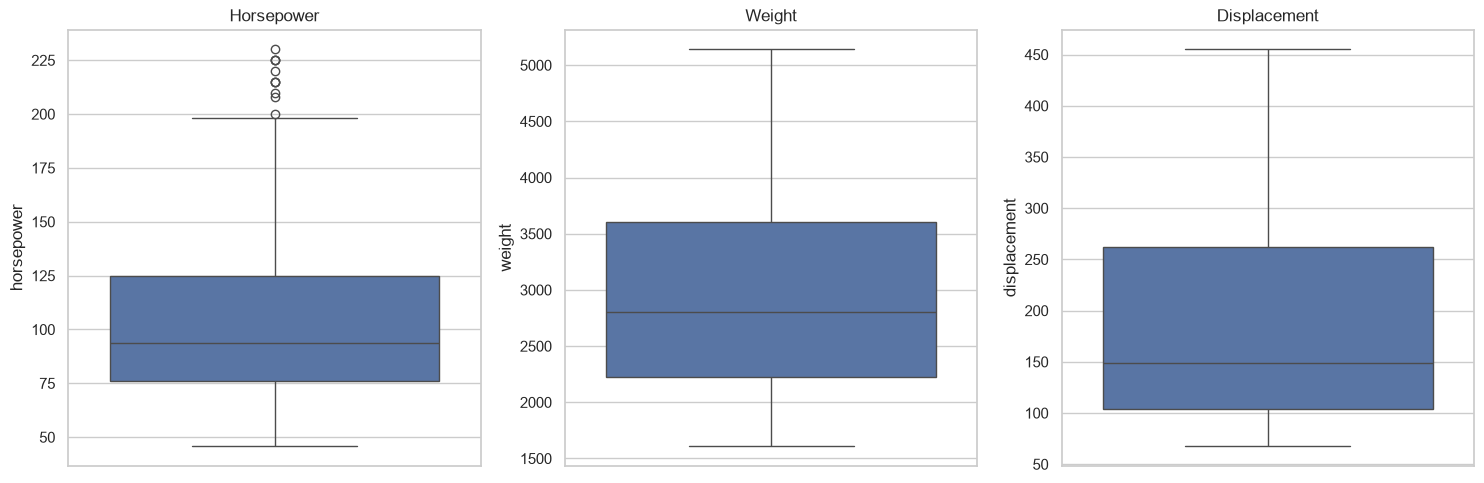

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.boxplot(y=df["horsepower"], ax=axes[0])
axes[0].set_title("Horsepower")
sns.boxplot(y=df["weight"], ax=axes[1])
axes[1].set_title("Weight")
sns.boxplot(y=df["displacement"], ax=axes[2])
axes[2].set_title("Displacement")
plt.tight_layout()
plt.show()

In [33]:
mazda_rotary = df[df["car_name"].str.contains("mazda rx", case=False)]
mazda_rotary[["car_name", "cylinders", "displacement", "horsepower", "weight", "mpg"]]

,car_name,cylinders,displacement,horsepower,weight,mpg
71,mazda rx2 coupe,3,70.0,97.0,2330.0,19.0
243,mazda rx-4,3,80.0,110.0,2720.0,21.5
334,mazda rx-7 gs,3,70.0,100.0,2420.0,23.7


**Observation:** The Mazda RX-2 and RX-4 stand out — only **3 cylinders** with **very low displacement** (70–80 cubic inches) but a horsepower similar to cars with much bigger engines. At first glance this looks like a data-entry error. It's actually a **genuine vehicle**: Mazda's RX models used a rotary (Wankel) engine, which produces relatively high horsepower from a small displacement and an unusual cylinder count. This is a real quirk of the data, not something to remove.

# Additional Question (Original Analysis)

**Question:** Did average fuel efficiency improve over the years covered by this dataset (1970–1982)?

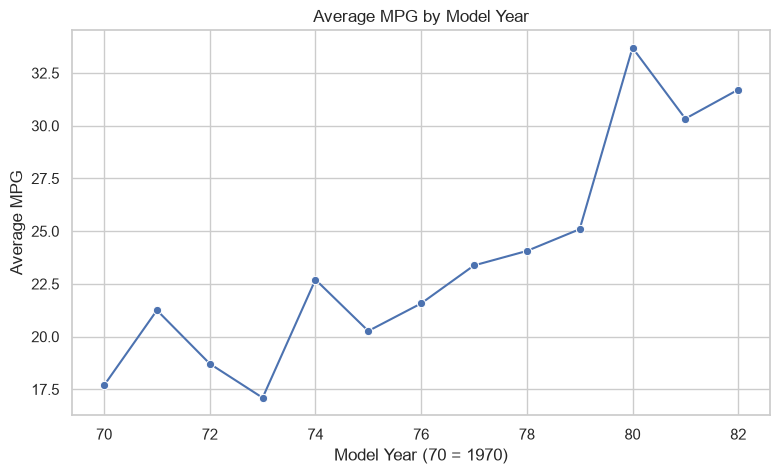

In [34]:
avg_mpg_by_year = df.groupby("model_year")["mpg"].mean()

plt.figure(figsize=(9, 5))
sns.lineplot(x=avg_mpg_by_year.index, y=avg_mpg_by_year.values, marker="o")
plt.title("Average MPG by Model Year")
plt.xlabel("Model Year (70 = 1970)")
plt.ylabel("Average MPG")
plt.show()

**Conclusion:** MPG roughly doubles from 1970 to 1982 — most likely the 1973 oil crisis pushing manufacturers toward smaller, lighter, more efficient cars.

# Key Findings

1. **Weight is the single strongest factor tied to mpg** — the correlation heatmap shows a -0.83 correlation, and the MPG vs Weight scatterplot shows a tight downward trend.
2. **Engine size and cylinder count tell the same story as weight** — displacement correlates at -0.80 with mpg, and the cylinder boxplot shows mpg dropping in clear steps from 4-cylinder to 8-cylinder cars.
3. **Fuel efficiency improved significantly over time** — the model-year line chart shows average mpg roughly doubling between 1970 and 1982.
4. **Origin matters** — the average-mpg-by-origin bar chart shows Japanese cars leading, followed by Europe, with American cars lowest, consistent with the USA having more high-displacement 8-cylinder cars in this dataset.
5. **Horsepower's relationship with mpg is non-linear** — the MPG vs Horsepower scatterplot shows a sharper drop at lower horsepower values that flattens out at the high end, unlike the more linear pattern seen with weight.
6. **The Mazda RX-2/RX-4 rotary-engine cars are genuine statistical outliers, not data errors** — the outlier boxplots and the low-displacement, low-cylinder-count values confirmed by the dataset checks reflect a real engine design, not a mistake in the data.

# Export Clean Dataset

In [35]:
df_export = df.drop(columns=["origin_name"])
df_export.to_csv("cleaned_auto_mpg.csv", index=False)

print("cleaned_auto_mpg.csv saved successfully.")
print("Final shape:", df_export.shape)

cleaned_auto_mpg.csv saved successfully.
Final shape: (398, 9)
